# 07 - Multi-Asset Analysis

## 1. Objective

Investigate historical relationships between National Grid (NG.L), its approved UK utility peers (SSE.L and SVT.L), and the FTSE 100 market benchmark.

This notebook uses the four equity-market acquisitions approved in Phase 2. It is designed to run from the project repository root and reads existing Raw acquisition files; it does not download data, overwrite Raw data, or create trading signals.

## 2. Research Questions

1. How have the four instruments behaved in terms of price performance, returns, volatility and drawdowns?
2. How closely have NG.L, SSE.L and SVT.L moved together?
3. How does NG.L relate to the FTSE 100 benchmark?
4. Are observed relationships stable across rolling windows or concentrated in particular periods?
5. What data limitations prevent descriptive relationships from being interpreted as predictive or causal?

## 3. Approved Research Universe

| Instrument | Provider symbol | Role | Acquisition ID |
|---|---|---|---|
| National Grid | `NG.L` | Pilot / target asset | `20261103T000455Z_8b505769` |
| SSE plc | `SSE.L` | UK utility peer | `20261103T002507Z_de101edb` |
| Severn Trent | `SVT.L` | UK utility peer | `20261103T002515Z_fdac38df` |
| FTSE 100 | `^FTSE` | UK equity market benchmark | `20261103T002524Z_9c7eb120` |

The acquisition register records 37,409 observations in total. The individual record counts and date ranges are documented in the Phase 2 progress register.

## 4. Methodology and Controls

- Use the acquired datasets only; no network access or fresh acquisition is performed.
- Prefer Adjusted Close for return and performance calculations when the field is available. Otherwise use Close and record the fallback.
- Preserve each instrument's own observation calendar. Do not forward-fill prices to manufacture synchronous observations.
- Calculate returns from each instrument's own consecutive available observations.
- Use pairwise complete observations for correlations.
- Use a common-date subset for relative performance comparisons.
- Treat the results as descriptive EDA, not causal inference or forecasting evidence.
- Do not silently repair OHLC anomalies, zero-volume observations or corporate-action issues identified in Phase 3.

## 5. Data Limitations Known Before Analysis

Phase 3 classified all four equity datasets as **Accept with limitations**. Recorded issues include missing and zero-volume observations, OHLC inconsistencies in NG.L, SSE.L and SVT.L, incomplete Yahoo Finance corporate-action information, historical NG.L rights issues requiring attention, and explicit GBP/GBp denomination handling.

The notebook must surface these limitations rather than silently correcting them. Technical acquisition integrity does not establish full financial data quality or strict point-in-time eligibility.

## 6. Imports and Configuration

The loader locates each acquisition by its immutable acquisition identifier under `data/raw/`. Parquet is preferred; CSV is used only if no Parquet file is found.

If the project uses a different repository layout, update `PROJECT_ROOT` explicitly rather than changing the acquisition identifiers.

In [7]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

PROJECT_ROOT = Path.cwd()
RAW_ROOT = PROJECT_ROOT / "data" / "raw"

ASSETS = {
    "NG.L": {
        "name": "National Grid",
        "role": "Pilot / target asset",
        "acquisition_id": "20261103T000455Z_8b505769",
    },
    "SSE.L": {
        "name": "SSE plc",
        "role": "Utility peer",
        "acquisition_id": "20261103T002507Z_de101edb",
    },
    "SVT.L": {
        "name": "Severn Trent",
        "role": "Utility peer",
        "acquisition_id": "20261103T002515Z_fdac38df",
    },
    "^FTSE": {
        "name": "FTSE 100",
        "role": "Market benchmark",
        "acquisition_id": "20261103T002524Z_9c7eb120",
    },
}

if not RAW_ROOT.exists():
    raise FileNotFoundError(
        f"Raw data directory not found: {RAW_ROOT}. "
        "Run this notebook from the project repository root or set PROJECT_ROOT."
    )

print(f"Project root: {PROJECT_ROOT.resolve()}")
print(f"Raw data root: {RAW_ROOT.resolve()}")
print(f"Configured instruments: {len(ASSETS)}")

Project root: /home/anderjcruz/projects/Quantitative-Trading-Strategy
Raw data root: /home/anderjcruz/projects/Quantitative-Trading-Strategy/data/raw
Configured instruments: 4


## 7. Data Loading and Provenance

The acquisition identifier is the primary locator. The loader prints the exact file selected for each instrument and reads an adjacent manifest when available.

No data is modified on disk.

In [8]:
def find_acquisition_file(acquisition_id: str) -> Path:
    """
    Locate the Parquet or CSV file associated with an acquisition.

    The acquisition directory follows the naming convention:
    acquisition_<acquisition_id>
    """
    acquisition_dir = f"acquisition_{acquisition_id}"

    # Prefer Parquet files.
    parquet_matches = list(
        RAW_ROOT.glob(f"**/{acquisition_dir}/*.parquet")
    )

    if len(parquet_matches) > 1:
        raise RuntimeError(
            f"Multiple Parquet files found for acquisition "
            f"{acquisition_id}: {parquet_matches}"
        )

    if parquet_matches:
        return parquet_matches[0]

    # Fall back to CSV if no Parquet file is available.
    csv_matches = list(
        RAW_ROOT.glob(f"**/{acquisition_dir}/*.csv")
    )

    if len(csv_matches) > 1:
        raise RuntimeError(
            f"Multiple CSV files found for acquisition "
            f"{acquisition_id}: {csv_matches}"
        )

    if csv_matches:
        return csv_matches[0]

    raise FileNotFoundError(
        f"No CSV or Parquet file found for acquisition "
        f"{acquisition_id} under {RAW_ROOT}"
    )


def read_market_file(path: Path) -> pd.DataFrame:
    if path.suffix.lower() == ".parquet":
        frame = pd.read_parquet(path)
    else:
        frame = pd.read_csv(path)

    if isinstance(frame.columns, pd.MultiIndex):
        frame.columns = [
            "_".join(str(part) for part in col if str(part) not in ("", "None"))
            for col in frame.columns.to_flat_index()
        ]
    return frame


def normalise_market_frame(frame: pd.DataFrame) -> pd.DataFrame:
    data = frame.copy()
    data.columns = [str(col).strip() for col in data.columns]

    # Identify a date column; otherwise use a datetime-like index.
    date_candidates = [
        col for col in data.columns
        if col.strip().lower() in {"date", "datetime", "timestamp", "time"}
    ]
    if date_candidates:
        date_col = date_candidates[0]
        data[date_col] = pd.to_datetime(data[date_col], errors="coerce", utc=True)
        data = data.dropna(subset=[date_col]).set_index(date_col)
    else:
        parsed_index = pd.to_datetime(data.index, errors="coerce", utc=True)
        if parsed_index.isna().all():
            raise ValueError("Could not identify a valid date column or datetime index.")
        data.index = parsed_index
        data.index.name = "Date"

    data.index = pd.DatetimeIndex(data.index).tz_convert(None).normalize()
    data = data.sort_index()
    data = data[~data.index.duplicated(keep="first")]

    # Match standard market fields without assuming a provider-specific column case.
    rename = {}
    for col in data.columns:
        token = str(col).strip().lower().replace(" ", "_")
        token = token.replace("-", "_")
        if token in {"open", "high", "low", "close", "volume"}:
            rename[col] = token.title()
        elif token in {"adj_close", "adjusted_close", "adjclose"}:
            rename[col] = "Adj Close"
    data = data.rename(columns=rename)

    for col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")
    return data


market_data = {}
provenance = []

for ticker, metadata in ASSETS.items():
    file_path = find_acquisition_file(metadata["acquisition_id"])
    raw_frame = read_market_file(file_path)
    clean_frame = normalise_market_frame(raw_frame)
    market_data[ticker] = clean_frame

    provenance.append({
        "ticker": ticker,
        "name": metadata["name"],
        "acquisition_id": metadata["acquisition_id"],
        "file": str(file_path.relative_to(PROJECT_ROOT)),
        "format": file_path.suffix.lower(),
        "rows_after_date_normalisation": len(clean_frame),
        "first_date": clean_frame.index.min(),
        "last_date": clean_frame.index.max(),
        "columns": ", ".join(map(str, clean_frame.columns)),
    })

provenance_df = pd.DataFrame(provenance)
display(provenance_df)

,ticker,name,acquisition_id,file,format,rows_after_date_normalisation,first_date,last_date,columns
0,NG.L,National Grid,20261103T000455Z_8b505769,data/raw/market/yahoo_finance/NG.L/acquisition...,.parquet,7890,1995-12-11,2026-11-02,"Adj Close, Close, Dividends, High, Low, Open, ..."
1,SSE.L,SSE plc,20261103T002507Z_de101edb,data/raw/market/yahoo_finance/SSE.L/acquisitio...,.parquet,9060,1991-06-17,2026-11-02,"Adj Close, Close, Dividends, High, Low, Open, ..."
2,SVT.L,Severn Trent,20261103T002515Z_fdac38df,data/raw/market/yahoo_finance/SVT.L/acquisitio...,.parquet,9455,1989-12-11,2026-11-02,"Adj Close, Close, Dividends, High, Low, Open, ..."
3,^FTSE,FTSE 100,20261103T002524Z_9c7eb120,data/raw/market/yahoo_finance/^FTSE/acquisitio...,.parquet,11004,1984-01-03,2026-11-02,"Adj Close, Close, High, Low, Open, Volume"


## 8. Data Inspection and Price-Series Selection

Adjusted Close is preferred for return analysis because it may incorporate provider adjustments for distributions and corporate actions. If it is unavailable, Close is used and the choice is explicitly recorded.

This preference does **not** resolve the Phase 3 concerns about incomplete corporate-action information or NG.L rights issues. Price denomination is not automatically converted because the source's GBP/GBp convention must be verified from the asset configuration and acquisition metadata.

In [9]:
def select_price_column(frame: pd.DataFrame) -> str:
    if "Adj Close" in frame.columns and frame["Adj Close"].notna().any():
        return "Adj Close"
    if "Close" in frame.columns and frame["Close"].notna().any():
        return "Close"
    raise ValueError("Neither a usable 'Adj Close' nor 'Close' field is available.")


price_columns = {
    ticker: select_price_column(frame)
    for ticker, frame in market_data.items()
}

price_series = pd.DataFrame({
    ticker: frame[price_columns[ticker]].rename(ticker)
    for ticker, frame in market_data.items()
})

price_series.index = pd.to_datetime(price_series.index)
price_series = price_series.sort_index()

price_series.head()

price_selection = pd.DataFrame([
    {
        "ticker": ticker,
        "selected_price_field": column,
        "has_open": "Open" in market_data[ticker].columns,
        "has_high": "High" in market_data[ticker].columns,
        "has_low": "Low" in market_data[ticker].columns,
        "has_close": "Close" in market_data[ticker].columns,
        "has_adjusted_close": "Adj Close" in market_data[ticker].columns,
        "has_volume": "Volume" in market_data[ticker].columns,
    }
    for ticker, column in price_columns.items()
])
display(price_selection)
display(price_series.describe().T)

,ticker,selected_price_field,has_open,has_high,has_low,has_close,has_adjusted_close,has_volume
0,NG.L,Adj Close,True,True,True,True,True,True
1,SSE.L,Adj Close,True,True,True,True,True,True
2,SVT.L,Adj Close,True,True,True,True,True,True
3,^FTSE,Adj Close,True,True,True,True,True,True


,count,mean,std,min,25%,50%,75%,max
NG.L,7889.0,729.743980,254.707572,210.663132,524.758301,700.552246,942.955933,1399.645630
SSE.L,9059.0,1068.934841,541.713159,214.376968,580.424988,1148.830078,1490.588623,2756.984375
SVT.L,9454.0,1567.793311,694.983732,372.487946,1024.260803,1433.139038,2120.903992,3306.000000
^FTSE,10820.0,5109.033086,2199.703119,986.900024,3135.700012,5537.800049,6674.725098,10910.599609


## 9. Historical Price Evolution

Raw price levels are shown for context only. Direct comparison of nominal price levels across different securities is not economically meaningful because share prices, index points and currency denominations differ.

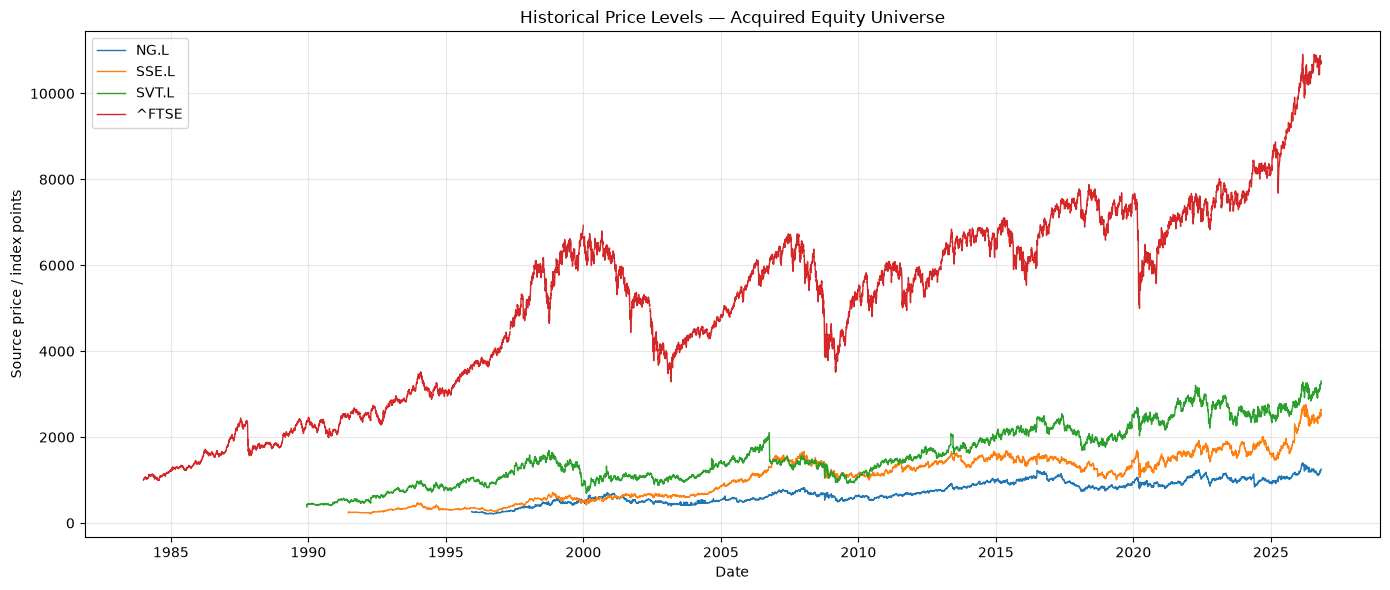

In [10]:
fig, ax = plt.subplots(figsize=(14, 6))
for ticker in price_series.columns:
    ax.plot(price_series.index, price_series[ticker], label=ticker, linewidth=1)
ax.set_title("Historical Price Levels — Acquired Equity Universe")
ax.set_xlabel("Date")
ax.set_ylabel("Source price / index points")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Daily Returns and Distributional Characteristics

Returns are calculated from consecutive available observations for each instrument. Because the source calendars may differ, a return row does not imply that every instrument traded on the same date.

,observations,mean_daily_return_pct,daily_volatility_pct,minimum_daily_return_pct,median_daily_return_pct,maximum_daily_return_pct,skewness,excess_kurtosis
NG.L,7888,0.034894,1.748997,-13.836307,0.012915,16.561659,0.263831,21.448795
SSE.L,9058,0.037291,1.461522,-12.168856,0.000000,16.839700,0.037779,9.251124
SVT.L,9453,0.035104,1.544573,-30.220978,0.000000,20.000012,-0.244475,29.724852
^FTSE,10684,0.026382,1.067066,-12.215566,0.058495,9.838667,-0.387761,9.775026


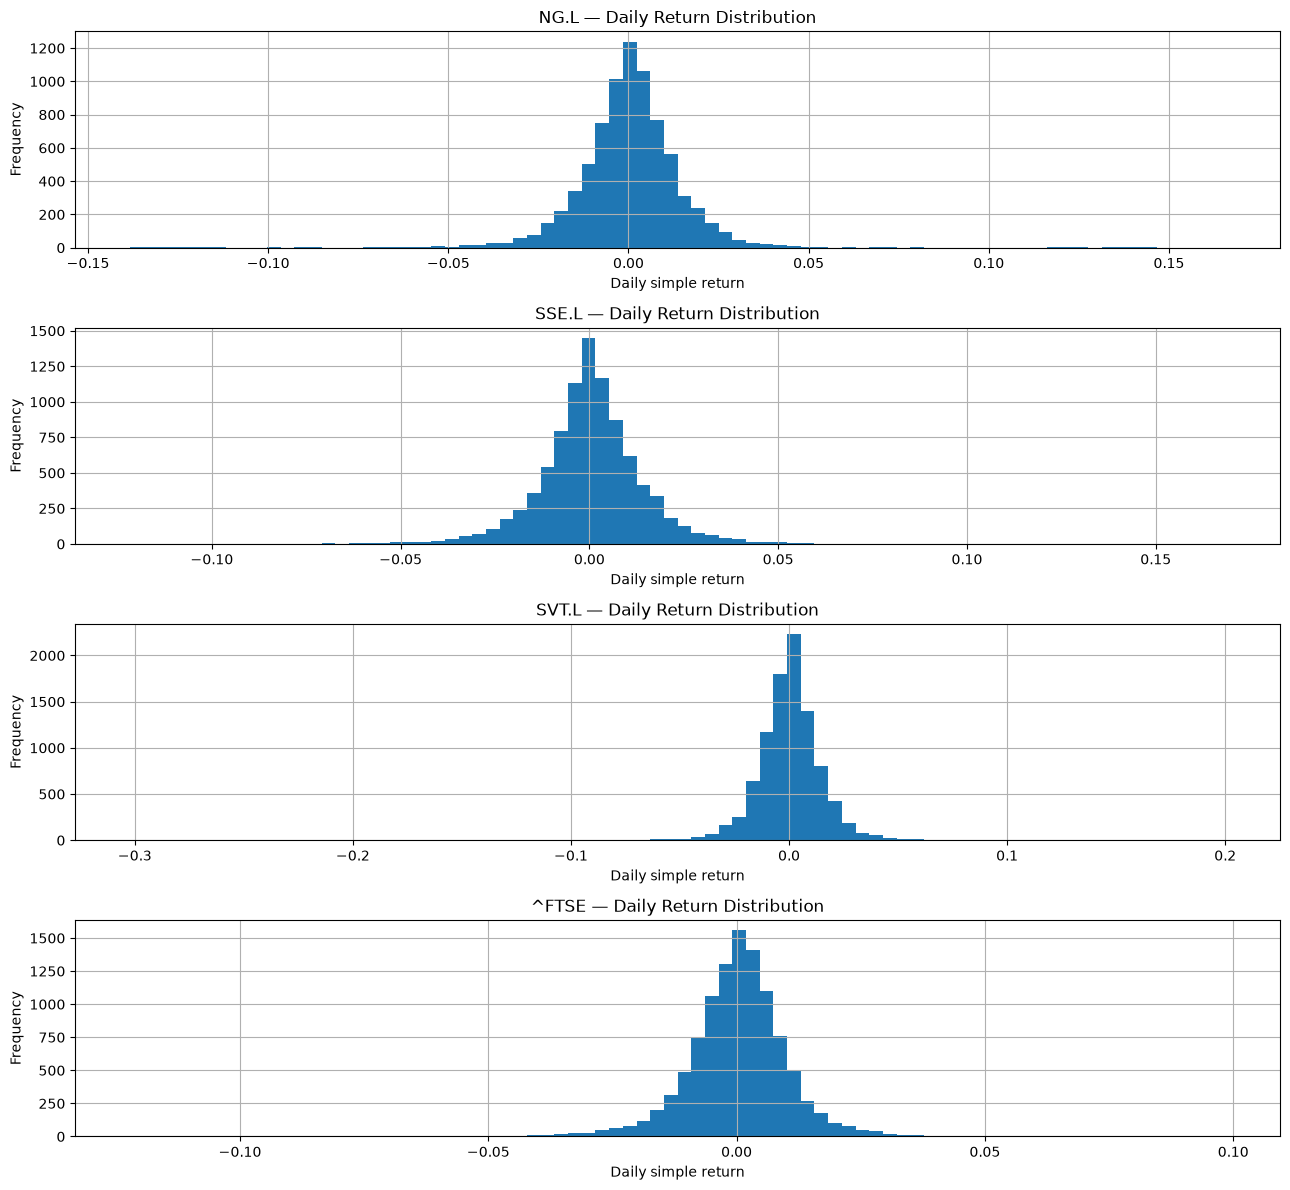

In [11]:
returns = price_series.pct_change(fill_method=None)
returns = returns.replace([np.inf, -np.inf], np.nan)

return_summary = pd.DataFrame({
    "observations": returns.count(),
    "mean_daily_return_pct": returns.mean() * 100,
    "daily_volatility_pct": returns.std() * 100,
    "minimum_daily_return_pct": returns.min() * 100,
    "median_daily_return_pct": returns.median() * 100,
    "maximum_daily_return_pct": returns.max() * 100,
    "skewness": returns.skew(),
    "excess_kurtosis": returns.kurtosis(),
})
display(return_summary)

fig, axes = plt.subplots(len(returns.columns), 1, figsize=(13, 3 * len(returns.columns)))
if len(returns.columns) == 1:
    axes = [axes]
for ax, ticker in zip(axes, returns.columns):
    returns[ticker].dropna().hist(bins=80, ax=ax)
    ax.set_title(f"{ticker} — Daily Return Distribution")
    ax.set_xlabel("Daily simple return")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## 11. Annualised Volatility

The annualisation below uses 252 trading observations as a conventional approximation. This is a descriptive convention, not a claim that all instruments share identical trading calendars or exactly 252 observations per year.

,annualised_volatility_pct
NG.L,27.764461
SSE.L,23.200935
SVT.L,24.519338
^FTSE,16.939141


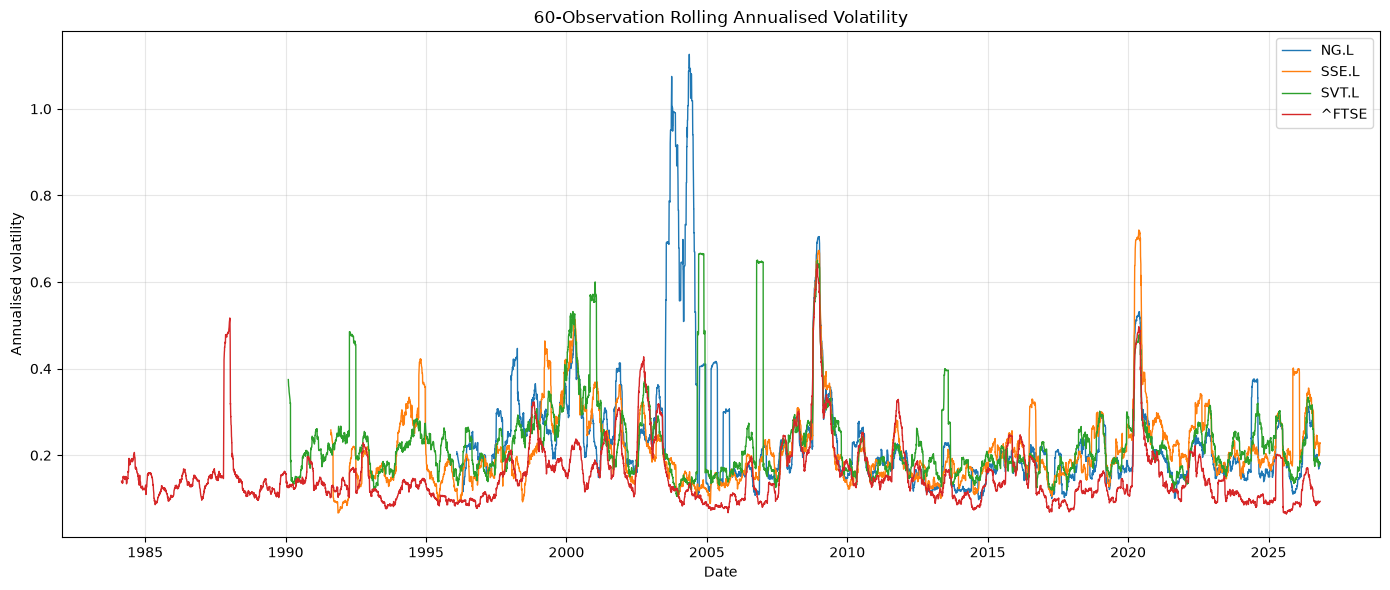

In [12]:
annualised_volatility = returns.std() * np.sqrt(252)
display((annualised_volatility * 100).rename("annualised_volatility_pct").to_frame())

rolling_volatility = returns.rolling(window=60, min_periods=40).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(14, 6))
for ticker in rolling_volatility.columns:
    ax.plot(rolling_volatility.index, rolling_volatility[ticker], label=ticker, linewidth=1)
ax.set_title("60-Observation Rolling Annualised Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualised volatility")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Common-Sample Relative Performance

To compare cumulative performance, the analysis uses dates on which all four selected price series have observations. The series are rebased to 100 at the first common date.

This common-date restriction can shorten the sample. It is preferable to forward-filling prices across non-trading dates, which could create artificial zero returns and distort correlations.

Common sample: 1995-12-11 to 2026-10-30
Common observations: 7,802


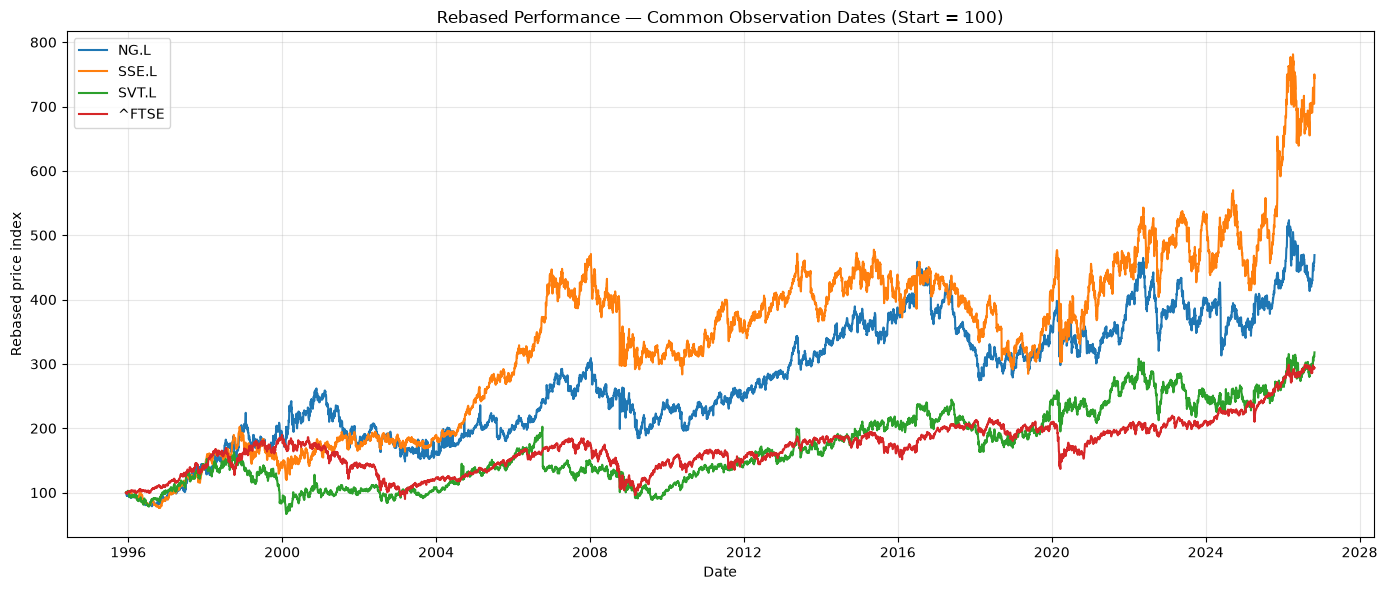

,common_period_price_change_pct
NG.L,369.159563
SSE.L,644.364068
SVT.L,217.956643
^FTSE,193.798076


In [13]:
common_prices = price_series.dropna(how="any")
if common_prices.empty:
    raise ValueError("No common observation dates across all four instruments.")

rebased = common_prices.div(common_prices.iloc[0]).mul(100)
print(f"Common sample: {common_prices.index.min().date()} to {common_prices.index.max().date()}")
print(f"Common observations: {len(common_prices):,}")

fig, ax = plt.subplots(figsize=(14, 6))
for ticker in rebased.columns:
    ax.plot(rebased.index, rebased[ticker], label=ticker)
ax.set_title("Rebased Performance — Common Observation Dates (Start = 100)")
ax.set_xlabel("Date")
ax.set_ylabel("Rebased price index")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

common_period_performance = (common_prices.iloc[-1] / common_prices.iloc[0] - 1) * 100
display(common_period_performance.rename("common_period_price_change_pct").to_frame())

## 13. Correlation Analysis

Pairwise correlations are calculated from returns on dates where both instruments have valid returns. The number of paired observations is reported alongside each correlation matrix.

Correlation is descriptive and does not establish causality, economic transmission or predictive usefulness.

,NG.L,SSE.L,SVT.L,^FTSE
NG.L,1.000000,0.395459,0.356600,0.378201
SSE.L,0.395459,1.000000,0.422948,0.434718
SVT.L,0.356600,0.422948,1.000000,0.363625
^FTSE,0.378201,0.434718,0.363625,1.000000


,NG.L,SSE.L,SVT.L,^FTSE
NG.L,7888,7888,7888,7738
SSE.L,7888,9058,9058,8846
SVT.L,7888,9058,9453,9215
^FTSE,7738,8846,9215,10684


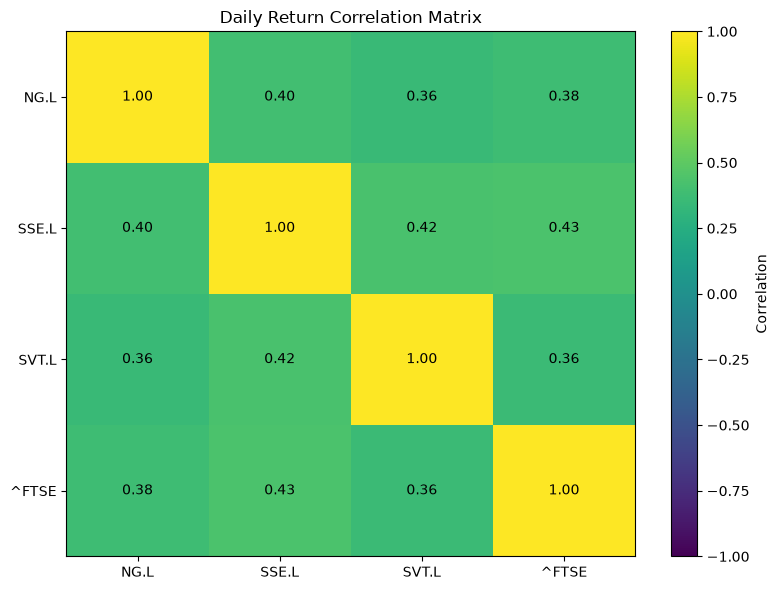

In [14]:
return_correlation = returns.corr(min_periods=60)
paired_counts = returns.notna().astype(int).T.dot(returns.notna().astype(int))

display(return_correlation)
display(paired_counts)

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(return_correlation, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(return_correlation.columns)), return_correlation.columns)
ax.set_yticks(range(len(return_correlation.index)), return_correlation.index)
ax.set_title("Daily Return Correlation Matrix")
for i in range(len(return_correlation.index)):
    for j in range(len(return_correlation.columns)):
        value = return_correlation.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

## 14. Rolling Correlations

Rolling correlations are calculated over 126 available return observations (approximately six months of trading observations). Each pair uses pairwise complete return observations within the rolling window.

Rolling windows overlap substantially; consecutive estimates are therefore not independent. The plots are intended to reveal time variation, not to provide formal statistical tests of structural breaks.

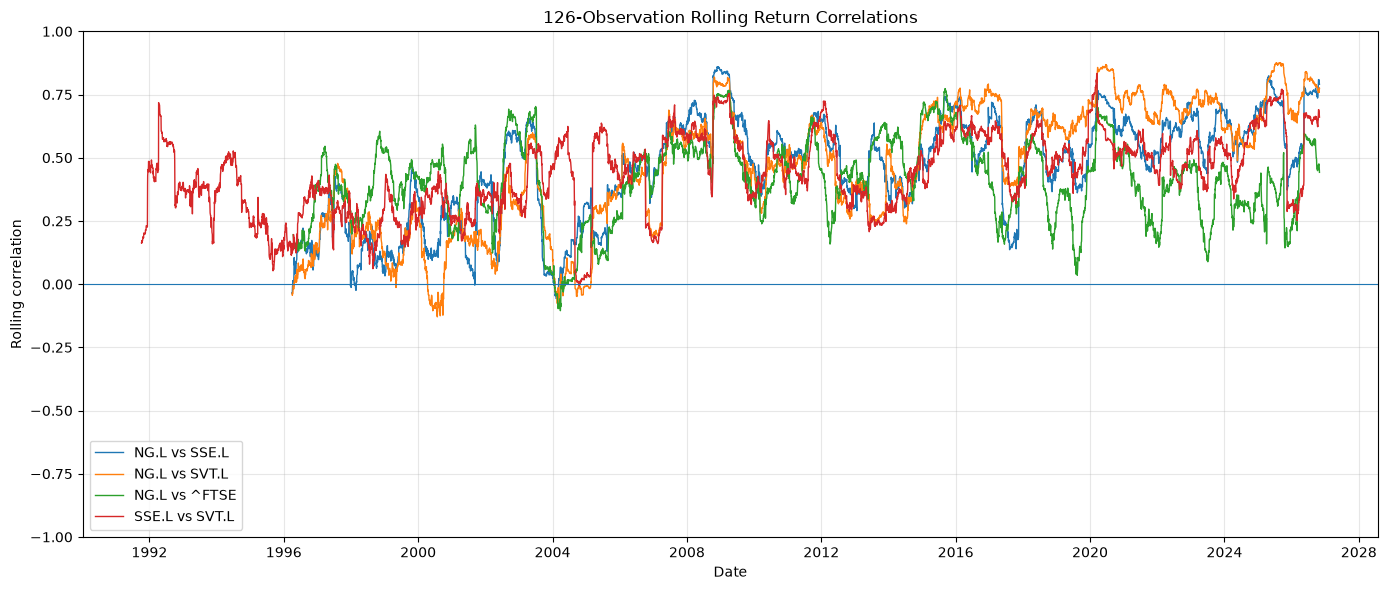

In [15]:
rolling_pairs = [
    ("NG.L", "SSE.L"),
    ("NG.L", "SVT.L"),
    ("NG.L", "^FTSE"),
    ("SSE.L", "SVT.L"),
]

fig, ax = plt.subplots(figsize=(14, 6))
for left, right in rolling_pairs:
    pair = returns[[left, right]].dropna()
    rolling_corr = pair[left].rolling(126, min_periods=80).corr(pair[right])
    ax.plot(rolling_corr.index, rolling_corr, label=f"{left} vs {right}", linewidth=1)
ax.axhline(0, linewidth=0.8)
ax.set_ylim(-1, 1)
ax.set_title("126-Observation Rolling Return Correlations")
ax.set_xlabel("Date")
ax.set_ylabel("Rolling correlation")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Drawdown Analysis

Drawdowns are calculated from each instrument's own selected price series and its running historical maximum. Because the adjusted-price history may not fully capture all corporate actions, drawdown estimates inherit the limitations recorded in Phase 3.

,maximum_observed_drawdown_pct
NG.L,-43.343312
SSE.L,-42.800996
SVT.L,-58.858194
^FTSE,-52.569913


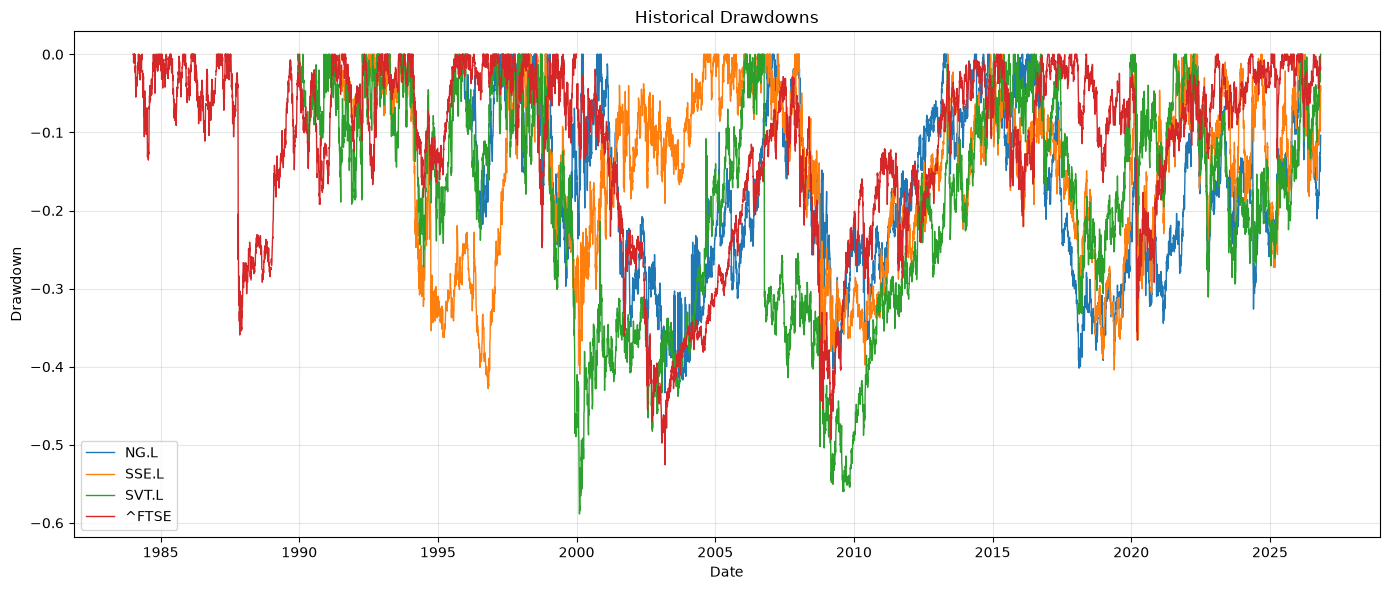

In [16]:
drawdown = price_series.div(price_series.cummax()).sub(1)
max_drawdown = drawdown.min() * 100
display(max_drawdown.rename("maximum_observed_drawdown_pct").to_frame())

fig, ax = plt.subplots(figsize=(14, 6))
for ticker in drawdown.columns:
    ax.plot(drawdown.index, drawdown[ticker], label=ticker, linewidth=1)
ax.set_title("Historical Drawdowns")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Trading Volume — Listed Equities

Trading volume is examined for NG.L, SSE.L and SVT.L where a Volume field exists. FTSE 100 index volume is not assumed to be comparable to individual share trading volume and is excluded from this comparison.

Volume units and provider conventions should be confirmed before cross-company comparisons are interpreted.

,count,mean,std,min,25%,50%,75%,max
NG.L,7890.0,8.480467e+06,6.366796e+06,0.0,4888476.75,6957213.0,10266398.25,97721684.0
SSE.L,9060.0,2.819038e+06,8.518163e+06,0.0,1328515.25,2342116.0,3570144.00,779874304.0
SVT.L,9455.0,8.163120e+05,8.524777e+05,0.0,350117.50,656171.0,1093131.50,31047690.0


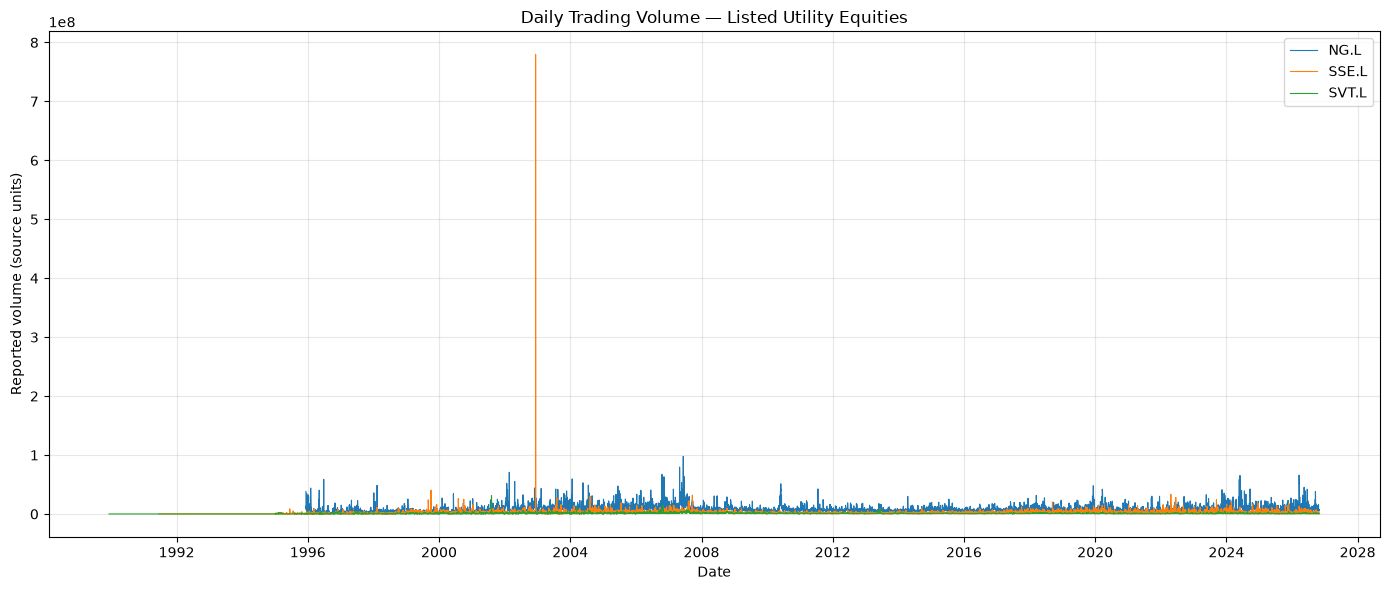

In [17]:
equity_tickers = ["NG.L", "SSE.L", "SVT.L"]
volume_series = {}
for ticker in equity_tickers:
    frame = market_data[ticker]
    if "Volume" in frame.columns:
        volume_series[ticker] = frame["Volume"]

if volume_series:
    volume_df = pd.DataFrame(volume_series)
    display(volume_df.describe().T)
    fig, ax = plt.subplots(figsize=(14, 6))
    for ticker in volume_df.columns:
        ax.plot(volume_df.index, volume_df[ticker], label=ticker, linewidth=0.8)
    ax.set_title("Daily Trading Volume — Listed Utility Equities")
    ax.set_xlabel("Date")
    ax.set_ylabel("Reported volume (source units)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No Volume fields were available for the three listed utility equities.")

## 17. Integrated Findings

The following cell generates a compact, data-dependent summary after the notebook has been executed. Interpret the results alongside the Phase 3 data-quality findings; do not convert descriptive relationships into predictive claims.

In [18]:
print("MULTI-ASSET EDA — EXECUTION SUMMARY")
print("=" * 60)
print(f"Assets analysed: {', '.join(price_series.columns)}")
print(f"Common-date sample: {common_prices.index.min().date()} to {common_prices.index.max().date()}")
print(f"Common-date observations: {len(common_prices):,}")

print("\nAnnualised volatility (%):")
display((annualised_volatility * 100).round(3).to_frame("annualised_volatility_pct"))

print("\nPairwise daily return correlations:")
display(return_correlation.round(3))

print("\nMaximum observed drawdown (%):")
display(max_drawdown.round(2).to_frame("maximum_drawdown_pct"))

print("\nPrice field selected per instrument:")
display(price_selection[["ticker", "selected_price_field"]])

MULTI-ASSET EDA — EXECUTION SUMMARY
Assets analysed: NG.L, SSE.L, SVT.L, ^FTSE
Common-date sample: 1995-12-11 to 2026-10-30
Common-date observations: 7,802

Annualised volatility (%):


,annualised_volatility_pct
NG.L,27.764
SSE.L,23.201
SVT.L,24.519
^FTSE,16.939



Pairwise daily return correlations:


,NG.L,SSE.L,SVT.L,^FTSE
NG.L,1.000,0.395,0.357,0.378
SSE.L,0.395,1.000,0.423,0.435
SVT.L,0.357,0.423,1.000,0.364
^FTSE,0.378,0.435,0.364,1.000



Maximum observed drawdown (%):


,maximum_drawdown_pct
NG.L,-43.34
SSE.L,-42.80
SVT.L,-58.86
^FTSE,-52.57



Price field selected per instrument:


,ticker,selected_price_field
0,NG.L,Adj Close
1,SSE.L,Adj Close
2,SVT.L,Adj Close
3,^FTSE,Adj Close


## 18. Interpretation and Research Hypotheses

Use the executed tables and figures to assess the following hypotheses:

1. **Utility peer relationship:** NG.L may exhibit return co-movement with SSE.L and SVT.L because all three operate in the UK utilities sector. Differences in business mix, regulation, capital structure and corporate events may produce material divergence.
2. **Broad market relationship:** NG.L may co-move with the FTSE 100, although its sector characteristics may cause periods of relative resilience or divergence.
3. **Time-varying dependence:** correlations may change across market conditions; a single full-sample correlation may conceal this variation.
4. **Risk concentration:** utility peers may share sector exposures, so adding them to a portfolio would not necessarily provide meaningful diversification.

These are hypotheses for further research. They are not established conclusions until supported by the executed results and subsequent robust statistical testing.

## 19. Data Limitations and Research Risks

The Phase 3 assessment identified the following limitations, which remain applicable:

- All four equity datasets are classified **Accept with limitations**.
- Missing and zero-volume observations were identified.
- OHLC inconsistencies were detected in NG.L, SSE.L and SVT.L.
- Adjusted Close and Close differences are consistent with dividend adjustments, but Yahoo Finance corporate-action information is incomplete.
- Historical NG.L rights issues require particular attention.
- Price denomination requires explicit GBP/GBp handling.
- File integrity and CSV/Parquet consistency do not prove complete trading-session coverage or full financial correctness.
- Historical provider data may not represent the information available to a market participant at the time.

Additional methodological limitations:
- The instruments have different inception dates and potentially different observation calendars.
- Pairwise correlations use different sample sizes; inspect the paired-observation matrix.
- Common-date rebasing discards dates where any instrument is missing.
- Adjusted Close is not a substitute for a fully validated corporate-action ledger.
- Correlation does not imply causation or forecasting value.
- No causal inference, feature selection, model training or strategy evaluation is performed here.

## 20. Conclusions

This notebook provides a descriptive multi-asset comparison of the approved initial equity universe: NG.L, SSE.L, SVT.L and the FTSE 100.

The analysis covers historical price behaviour, daily returns, distributional characteristics, annualised and rolling volatility, common-sample relative performance, return correlations, rolling correlations, drawdowns and available trading volume.

The notebook does not establish that peer equities or the FTSE 100 improve forecasts of NG.L. It does not approve any variable as a model feature and does not generate trading signals.

All conclusions remain conditional on the Phase 3 data-quality limitations, particularly corporate-action completeness, OHLC inconsistencies and price denomination. Any future predictive use requires point-in-time controls, consistent temporal alignment and out-of-sample ablation against a target-asset-only baseline.

## 21. Next Steps and Phase 4 Handover

1. Execute this notebook from the project repository root using the existing acquired files.
2. Investigate and resolve any file-discovery or schema mismatch without changing immutable Raw data.
3. Review outputs and document data-dependent findings, including paired sample sizes.
4. Validate Notebook 08 through a clean kernel execution.
5. Review Notebook 06, Notebook 07 and Notebook 08 together.
6. Prepare the integrated Phase 4 report and update decision and risk logs.
7. Request explicit approval to close Phase 4.

**Phase boundary:** no Phase 5 financial time-series investigation, feature engineering, forecasting or strategy work is started by this notebook.